##**Лабораторная  работа №2**
**Цель**: Освоение навыков решения задачи классификации с использованием модели логистической регрессии. Применение методов регуляризации (L1, L2) для борьбы с переобучением. Подбор гиперпараметров модели с использованием кросс-валидации и поиска по сетке.

**Задачи работы**

1. **Загрузить и изучить датасет** `Telco Customer Churn`:
   - Ознакомиться с признаками и целевой переменной.
   - Провести предварительный анализ: распределения, корреляции, визуализации.

2. **Подготовить данные**:
   - Обработать пропуски и закодировать категориальные признаки (LableEncoder, OneHotEncoder).
   - Удалить признаки с высокой корреляцией.
   - Разделить данные на обучающую и тестовую выборки.
   - Применить стандартизацию признаков.

3. **Обучить и оценить логистическую регрессию без регуляризации**:
   - Построить базовую модель.
   - Оценить качество с помощью метрик `accuracy`, `precision`, `recall`, `f1`.
   - Построить и проанализировать матрицу ошибок.

4. **Подобрать гиперпараметры с помощью `GridSearchCV`**:
   - Изучить влияние методов регуляризации `penalty` (L1, L2), `C` и `class_weight` на модель.
   - Применить кросс-валидацию для поиска оптимальной комбинации параметров.
   - Выбрать модель с наилучшей метрикой `f1`.

5. **Оценить качество лучшей модели**:
   - Сделать предсказания на тестовой выборке.
   - Сравнить метрики с предыдущей моделью.
   - Построить и проанализировать матрицу ошибок для лучшей модели.

6. **Проанализировать важность признаков**:
   - Извлечь и визуализировать коэффициенты обученной модели.
   - Определить топ-10 самых важных признаков.
   - Сделать выводы о влиянии признаков на предсказание оттока.


**<font color="red">Обратите внимание</font> - пункты 2-5 содержат вопросы (в конце), на которые нужно ответить письменно**

In [26]:
# Ячейка для подключения библиотек - просто запустите ее

# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Для работы с датасетом
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, PolynomialFeatures
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Для загрузки датасета с Kaggle
import kagglehub

### Ссылки на документацию для всех необходимых библиотечных моделей и функций

- [pandas.read_csv](https://pandas.pydata.org/docs/stable/reference/api/pandas.read_csv.html) — загрузка данных из CSV-файла.
- [pandas.DataFrame.info](https://pandas.pydata.org/docs/stable/reference/api/pandas.DataFrame.info.html) — информация о типах данных и пропусках.
- [pandas.DataFrame.describe](https://pandas.pydata.org/docs/stable/reference/api/pandas.DataFrame.describe.html) — статистики по числовым признакам.
- [pandas.DataFrame.hist](https://pandas.pydata.org/docs/stable/reference/api/pandas.DataFrame.hist.html) — гистограммы для числовых признаков.
- [seaborn.countplot](https://seaborn.pydata.org/generated/seaborn.countplot.html) — столбчатая диаграмма для категориальных признаков.
- [seaborn.heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) — тепловая карта (например, для матрицы корреляций).
- [sklearn.preprocessing.LabelEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html) — кодирование категориальных признаков в числа.
- [sklearn.preprocessing.OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) — бинарное кодирование категориальных признаков.
- [sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) — стандартизация признаков.
- [sklearn.model_selection.train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) — разделение на обучающую и тестовую выборки.
- [sklearn.linear_model.LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) — модель логистической регрессии.
- [sklearn.model_selection.GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) — подбор гиперпараметров с кросс-валидацией.
- [sklearn.metrics.accuracy_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) — метрика точности.
- [sklearn.metrics.classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html) — отчет по метрикам классификации.
- [sklearn.metrics.confusion_matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html) — матрица ошибок.
- [kagglehub.dataset_download](https://github.com/Kaggle/kagglehub#python-sdk) — загрузка датасета с Kaggle.

## **1. Загрузка датасета**

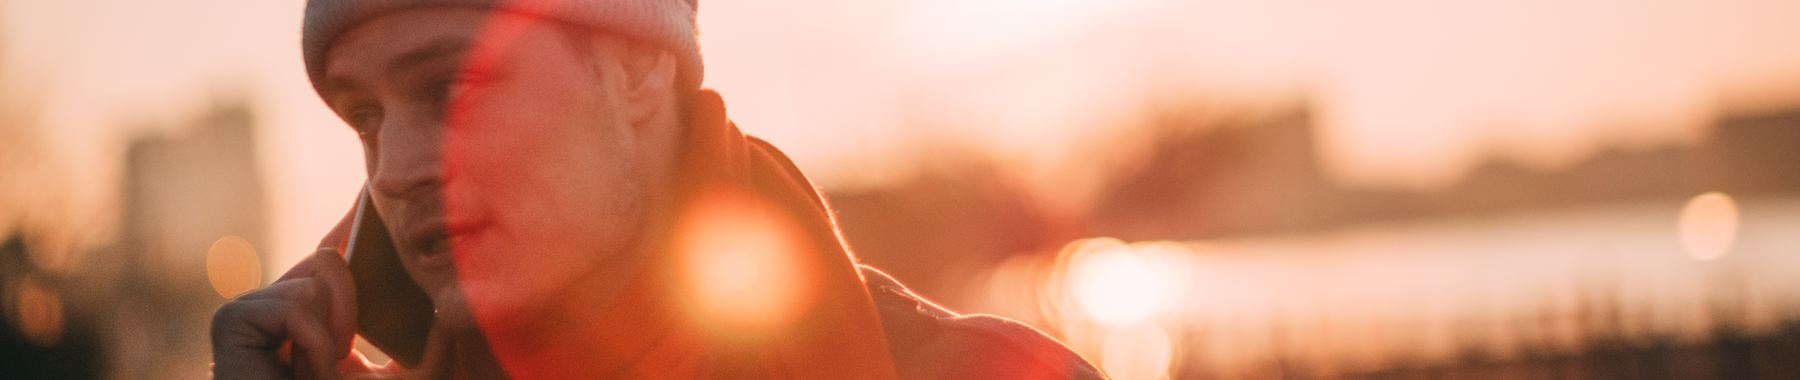

##### **Описание датасета**

**Название:** Telco Customer Churn  
**Источник:** [Kaggle Dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)  
**Описание:**  
Датасет содержит информацию о клиентах телекоммуникационной компании и их поведании. Он используется для решения задачи **бинарной классификации**, где целевая переменная — **факт оттока клиента (Churn)**. Цель — обучить модель, которая сможет предсказать, уйдёт ли клиент от оператора связи.

**Целевая переменная:**
- `Churn` — ушёл ли клиент (Yes/No), бинарная категориальная переменная (после кодирования: 1 — ушёл, 0 — остался).

**Признаки:**
- `gender` — пол клиента (Male/Female), категориальный признак.
- `SeniorCitizen` — является ли клиент пенсионером (0/1), бинарный признак.
- `Partner` — наличие партнёра (Yes/No), бинарный признак.
- `Dependents` — наличие иждивенцев (Yes/No), бинарный признак.
- `tenure` — срок пользования услугами (месяцы), непрерывная величина.
- `PhoneService` — наличие телефонной услуги (Yes/No), бинарный признак.
- `MultipleLines` — наличие нескольких линий (Yes/No/No phone service), категориальный признак.
- `InternetService` — тип интернет-провайдера (DSL/Fiber optic/No), категориальный признак.
- `OnlineSecurity` — наличие онлайн-безопасности (Yes/No/No internet service), категориальный признак.
- `OnlineBackup` — наличие онлайн-бэкапа (Yes/No/No internet service), категориальный признак.
- `DeviceProtection` — наличие защиты устройства (Yes/No/No internet service), категориальный признак.
- `TechSupport` — наличие технической поддержки (Yes/No/No internet service), категориальный признак.
- `StreamingTV` — наличие стриминга ТВ (Yes/No/No internet service), категориальный признак.
- `StreamingMovies` — наличие стриминга фильмов (Yes/No/No internet service), категориальный признак.
- `Contract` — тип контракта (Month-to-month/One year/Two year), категориальный признак.
- `PaperlessBilling` — безбумажный расчёт (Yes/No), бинарный признак.
- `PaymentMethod` — способ оплаты (например, Electronic check, Mailed check), категориальный признак.
- `MonthlyCharges` — ежемесячная плата (доллары США), непрерывная величина.
- `TotalCharges` — общая сумма платежей (доллары США), непрерывная величина (иногда содержит пробелы, требует обработки).

**Пропущенные значения:** Присутствуют в столбце `TotalCharges`, где пустые значения обозначены пробелами (` `).

**Примечание:**  
Для задач машинного обучения столбец `customerID` обычно исключается, а категориальные признаки требуют кодирования (например, `OneHotEncoder` или `LabelEncoder`).

**Задание:**  
Загрузите датасет `Telco Customer Churn` с помощью библиотеки `kagglehub`.  
Для этого выполните следующие шаги:
1. Скачайте датасет, используя команду `kagglehub.dataset_download("blastchar/telco-customer-churn")`.
2. Выведите в консоль путь к скачанным файлам (его вернет метод `dataset_download`).
3. Сформируйте полный путь, добавив к пути название файла `WA_Fn-UseC_-Telco-Customer-Churn.csv`.
4. Загрузите данные из этого файла в переменную `df`, используя `pd.read_csv()`.
5. Выведите первые 5 строк датасета с помощью `df.head()`.

In [33]:
from pathlib import Path


path = kagglehub.dataset_download(
    'blastchar/telco-customer-churn',
    force_download=True
)
file_path = Path(path) / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

file_path

100%|██████████| 172k/172k [00:00<00:00, 590kB/s]

Extracting files...


PosixPath('/Users/generalsuslik/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [34]:
df = pd.read_csv(file_path)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## **2. Предварительный анализ данных**

**Задание:**
- Выведите информацию о типах данных и наличии пропусков с помощью `df.info()`. Это покажет, сколько строк и столбцов в датасете, а также типы данных.
- Выведите размер датасета (количество строк и столбцов) с помощью `df.shape`.
- Постройте основные статистики для числовых признаков с помощью `df.describe()`. Это покажет среднее, стандартное отклонение, минимум, максимум и т.д.
- Выведите распределение целевой переменной `Churn` с помощью `df['Churn'].value_counts()`, чтобы понять, сбалансированы ли классы.
- Постройте столбчатую диаграмму (`sns.countplot`) для визуализации распределения `Churn`.


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [17]:
df.shape

(7043, 21)

In [21]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [22]:
churn = df.Churn
churn.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

<Axes: xlabel='Churn', ylabel='count'>

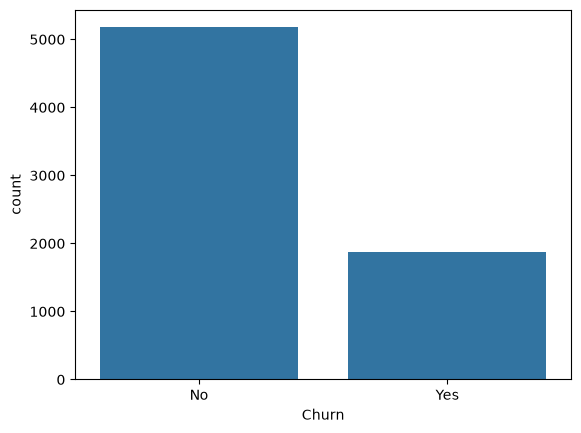

In [59]:
sns.countplot(x='Churn', data=df)

**Задание**  
- Определите и выведите список категориальных признаков, используя `df.select_dtypes(include=['object'])`.
- Проверьте наличие пропусков в датасете.
- Замените пустые строки (`" "`, `""`) на `NaN`, используя `df.replace` с заменой их на `np.nan`.
- Удалите строки, содержащие пропущенные значения, и выведите размер обновленного датасета.
- Преобразуйте столбец `TotalCharges` в числовой тип (`float`), используя `pd.to_numeric(...)`.


In [36]:
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
categorical_cols

['customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'TotalCharges',
 'Churn']

In [37]:
print("Empty stuff before replacement", df.isna().sum())

df = df.replace([' ', ''], np.nan)

print("end==Empty stuff after replacement", df.isna().sum())

Empty stuff before replacement customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
end==Empty stuff after replacement customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11

In [38]:
rows_before = len(df)
shape_before = df.shape

df = df.dropna()

print("removed rows:", rows_before - len(df))
print("shape before removing rows with NaN values:", shape_before)
print("shape after removing rows with NaN values:", df.shape)

removed rows: 11
shape before removing rows with NaN values: (7043, 21)
shape after removing rows with NaN values: (7032, 21)


In [39]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges']).astype(float)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Задание**  
- Постройте **гистограммы** для всех **числовых** признаков с помощью `df[numeric_cols].hist()`. Не забудьте указать `figsize`, `bins` и `layout`.
- Постройте **столбчатые диаграммы** (`sns.countplot`) для всех **категориальных** признаков.

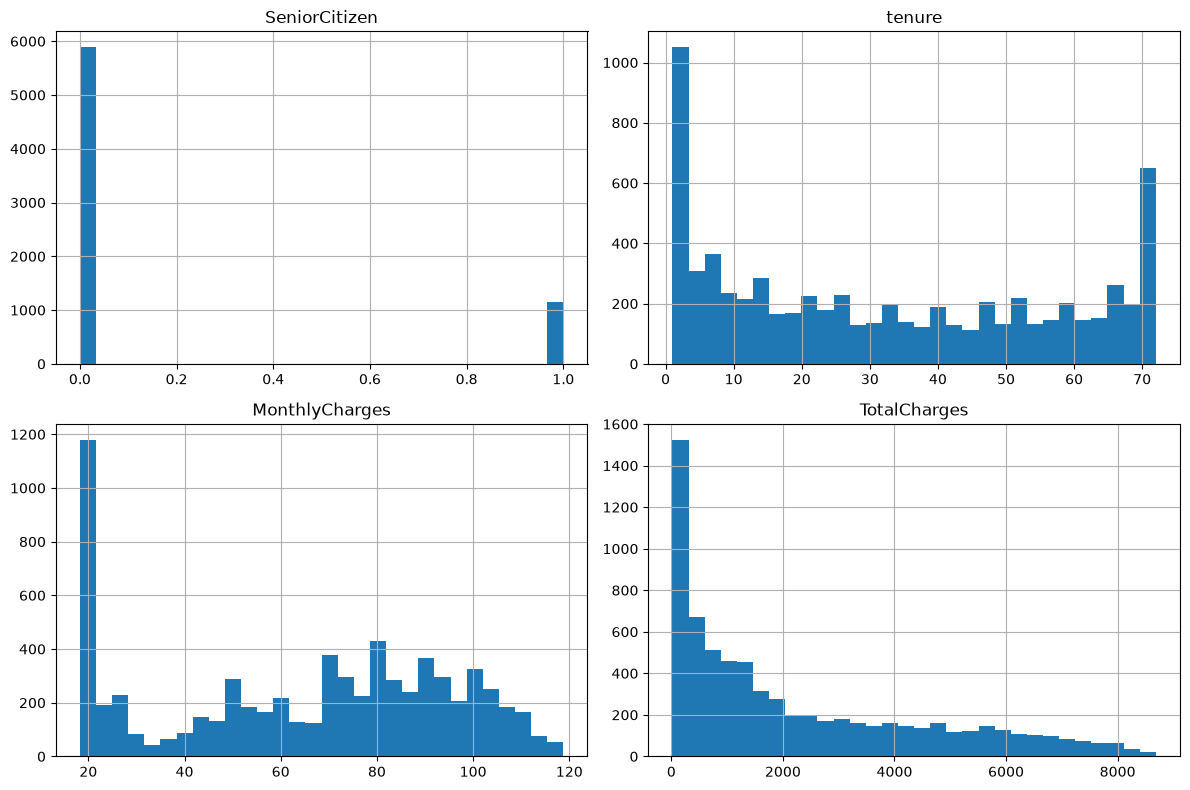

In [40]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()

df[numeric_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

**Ответьте на вопросы:**
- Почему дисбаланс классов при решении задачи классификации может быть проблемой?
- Сбалансированы ли классы в целевой переменной `Churn`?
- Как выбрать категориальные признаки с помощью `df.select_dtypes()`? Почему важно различать типы признаков?
- Почему пустые строки вроде `" "` или `""` могут быть проблемой? Как их можно обнаружить и исправить?
- Зачем преобразовывать столбец `TotalCharges` в числовой тип? Какие проблемы могут возникнуть, если этого не сделать?

##### **Ответы на вопросы:**

1. При дисбалансе модель может предсказывать более частый класс чаще, чем более редкий. (Если всегда предсказыть NO, accuracy 73.5%)
2. Нет, No превосходит по количеству Yes
3. категориальные -- неравномерно распределены и их числовое представление не значит, что кто-то важнее другого. Категориальные надо кодировать
4. Строки " ", "" не распознаются isna() и могут мешать преобразованию в числа
5. Столбец -- сумма платежей. Логично, чтобы это был числовой тип. Если оставить строки, столбец не попадёт в стандартные числовые статистики и корреляции и не сможет напрямую использоваться как числовой признак в модел

## **3. Предобработка данных**

**Задание:**
- Удалите столбец `customerID`, так как он не несёт полезной информации для модели, с помощью `df.drop()`.
- Закодируйте целевую переменную `Churn` в бинарный формат (0 и 1), используя `LabelEncoder`.
- Проверьте результат, выведя первые 5 строк датасета.

In [41]:
df = df.drop(columns=['customerID'])

churn_encoder = LabelEncoder()
df['Churn'] = churn_encoder.fit_transform(df['Churn'])

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


**Задание:**  
Закодируйте категориальные признаки.
- Определите, какие столбцы имеют 2 уникальных значения, а какие — больше:
  - Используйте `df.select_dtypes(include=['object'])` для получения категориальных столбцов.
  - Проверьте количество уникальных значений каждого столбца с помощью `df[...].nunique()`.

- Примените `LabelEncoder` к бинарным столбцам.
- Примените `OneHotEncoder` к множественным столбцам.
- Выведите размер датасета и названия столбцов после кодирования.

In [42]:
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
print("Categorical columns:", categorical_cols)

binary_cols = [col for col in categorical_cols if df[col].nunique() == 2]
multiclass_cols = [col for col in categorical_cols if df[col].nunique() > 2]

for col in binary_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

ohe = OneHotEncoder(sparse_output=False)
encoded = ohe.fit_transform(df[multiclass_cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(multiclass_cols),
    index=df.index
)

print("Shape:", encoded_df.shape)
print("Cols:", encoded_df.columns.tolist())

df = pd.concat(
    [df.drop(columns=multiclass_cols), encoded_df],
    axis=1,
)

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Shape: (7032, 31)
Cols: ['MultipleLines_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank tra

**Задание:**
- Вычислите матрицу корреляций для всех признаков с помощью `df.corr()`.
- Найдите пары признаков с высокой корреляцией (значение более `0.99` по **модулю**).
- Выведите найденные пары признаков с высокой корреляцией.
- Удалите один из признаков в каждой паре с высокой корреляцией.
- Выведите размер датасета после удаления коррелирующих признаков.

In [43]:
corr_matrix = df.corr()

feature_corr = corr_matrix.drop(index="Churn", columns="Churn").abs()

upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr = upper.stack()
high_corr = high_corr[high_corr > 0.99]
high_corr

PhoneService                          MultipleLines_No phone service          1.0
InternetService_No                    OnlineSecurity_No internet service      1.0
                                      OnlineBackup_No internet service        1.0
                                      DeviceProtection_No internet service    1.0
                                      TechSupport_No internet service         1.0
                                      StreamingTV_No internet service         1.0
                                      StreamingMovies_No internet service     1.0
OnlineSecurity_No internet service    OnlineBackup_No internet service        1.0
                                      DeviceProtection_No internet service    1.0
                                      TechSupport_No internet service         1.0
                                      StreamingTV_No internet service         1.0
                                      StreamingMovies_No internet service     1.0
OnlineBackup_No 

In [44]:
cols_to_drop = high_corr.index.get_level_values(1).unique().tolist()
df = df.drop(columns=cols_to_drop)

print("removed columns:", cols_to_drop)
df.shape

removed columns: ['MultipleLines_No phone service', 'OnlineSecurity_No internet service', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingTV_No internet service', 'StreamingMovies_No internet service']


(7032, 34)

**Задание:**
- Постройте матрицу корреляции для всех числовых признаков в модифицированном датасете.
- Постройте тепловую карту (`sns.heatmap`) с параметрами:
    - `annot=True` — чтобы отображать значения корреляции в ячейках.
    - `cmap='coolwarm'` — цветовая схема.
    - `figsize=(15, 10)` — размер фигуры.

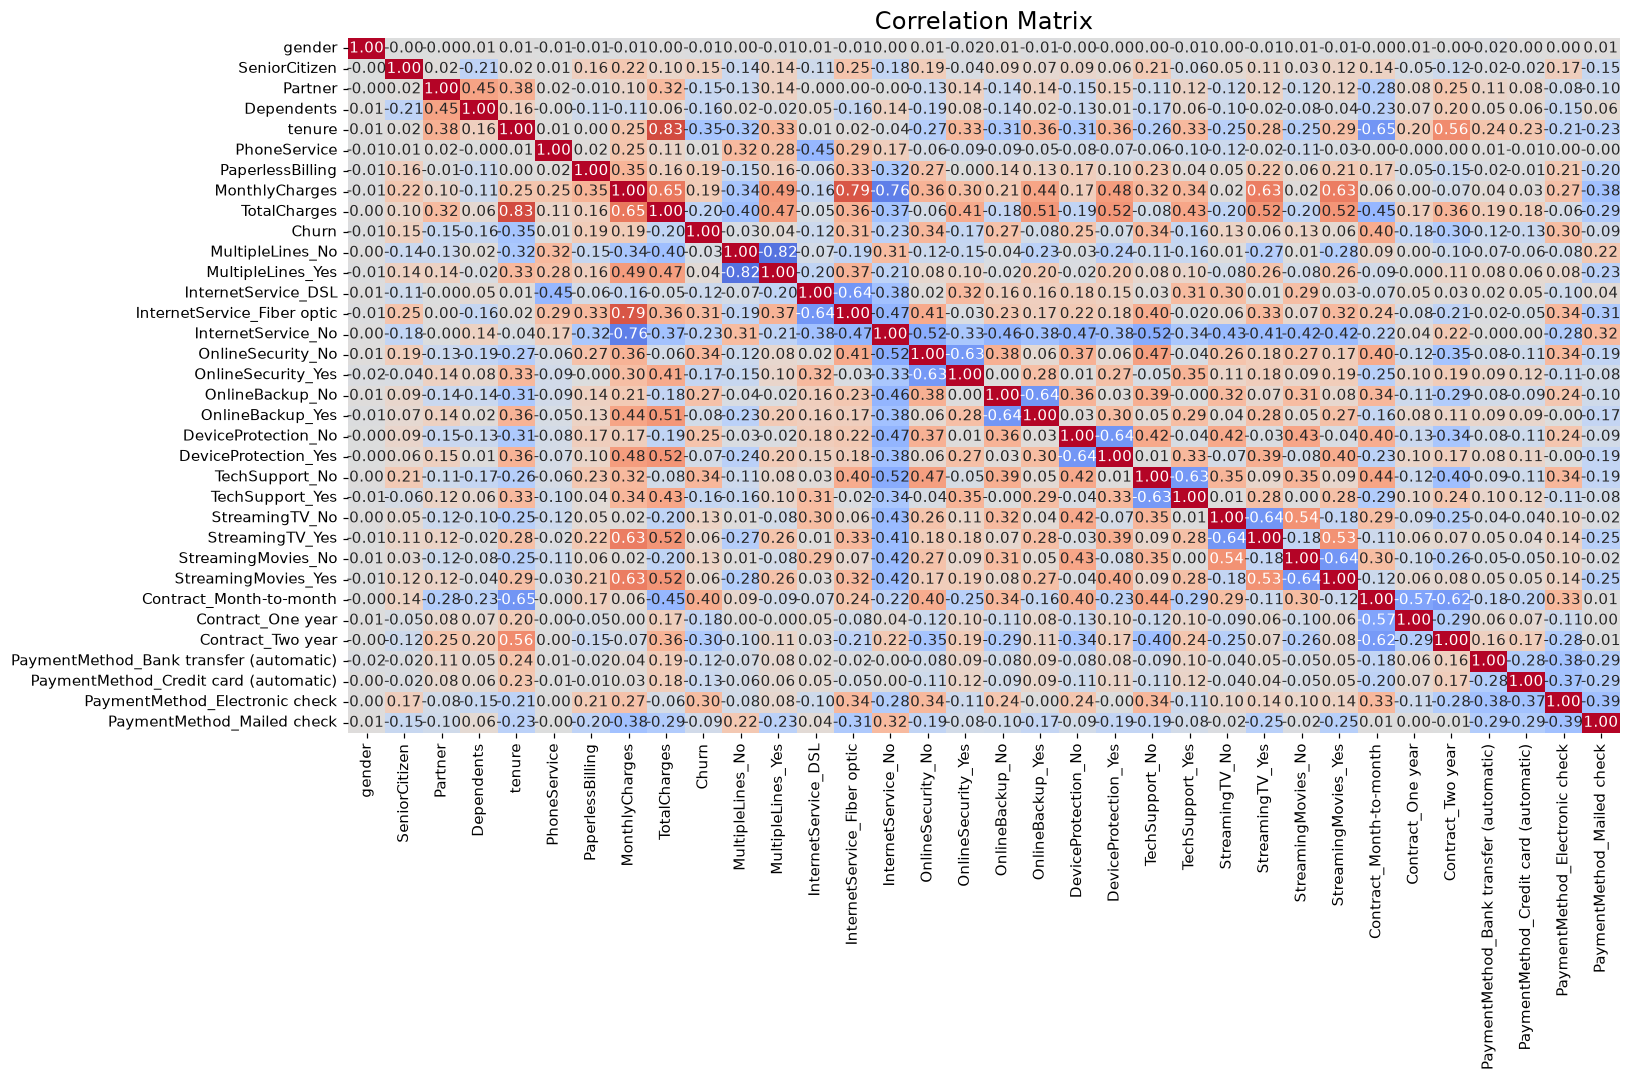

In [17]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(15, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    cbar=False
)

plt.title('Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.show()

**Задание:**
- Разделите датасет на признаки `X` и целевую переменную `y`:
  - Признаки `X` — это все столбцы, кроме `Churn`.
  - Целевая переменная `y` — столбец `Churn`.
- Разделите данные на обучающую и тестовую выборки:
  - Используйте `train_test_split` из `sklearn.model_selection`.
  - Установите `test_size=0.2`, чтобы 20% данных пошло на тест.
  - Установите `random_state=42` для воспроизводимости.
  - Установите `stratify=y`, чтобы сохранить пропорции классов в обеих выборках.
- Выведите размеры обучающей и тестовой выборок.

In [49]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5625, 33)
X_test shape: (1407, 33)
y_train shape: (5625,)
y_test shape: (1407,)


**Задание:**
- Выполните стандартизацию данных с использованием `StandardScaler` из `sklearn.preprocessing`.

In [52]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (5625, 33)
X_test_scaled shape: (1407, 33)


**Ответьте на вопросы:**
- Зачем кодировать целевую переменную в бинарный формат?
- Зачем различать бинарные и множественные категориальные признаки? Почему здесь для них используются разные методы кодирования?
- Как `LabelEncoder` и `OneHotEncoder` изменяют структуру данных? В каких случаях какой метод предпочтительнее?
- Что показывает матрица корреляций? Почему некоторые признаки обладают корреляцией `1` (обратите внимание на названия категорий)
- Зачем использовать `stratify=y` при разделении данных? Как это влияет на распределение классов в обучающей и тестовой выборках?
- Почему стандартизация признаков важна для логистической регрессии? Как она влияет на обучение модели?

##### **Ответы на вопросы:**

1. Чтобы было числовое кодирование классов. Для единообразной интерпретации предсказаний
2. Для бинарного признака достаточно одного столбца со значениями 0 и 1. Для признаков с несколькими категориями простое присвоение чисел может создать искусственный порядок и расстояния между категориями. Поэтому по заданию бинарные признаки кодируются через LabelEncoder, а многокатегориальные — через OneHotEncoder.
3. LabelEncoder заменяет категории целочисленными кодами, сохраняя один столбец. Он предназначен для кодирования целевой переменной; в этой работе также применяется к бинарным признакам. OneHotEncoder создаёт отдельный столбец для каждой категории со значениями 0 или 1. Он подходит для признаков с несколькими категориями без естественного порядка.
4. Матрица показывает направление и силу линейной связи между числовыми столбцами. Коэффициент около 1 означает сильную прямую связь, около -1 — обратную, около 0 — слабую линейную связь. После кодирования некоторые столбцы дублируют друг друга. Например, OnlineSecurity_No internet service и OnlineBackup_No internet service отмечают одних и тех же клиентов без интернета, поэтому их корреляция равна 1.
5. Параметр сохраняет примерно одинаковые доли классов в обучающей и тестовой выборках. Это важно при дисбалансе Churn: обе выборки должны содержать представительное количество клиентов с оттоком и без него.
6. Признаки имеют разные масштабы: например, срок обслуживания измеряется месяцами, а общая сумма платежей — тысячами денежных единиц. Стандартизация приводит их к сопоставимому масштабу, улучшает сходимость оптимизации и делает действие регуляризации более равномерным. Параметры масштабирования вычисляются только на обучающей выборке, затем применяются к тестовой.

## **4. Обучение обычной логистической регрессии и ее оценка**

**Задание:**
- Создайте модель логистической регрессии `LogisticRegression` с параметрами:
  - `C=1000` — очень слабая регуляризация.
  - `random_state=42` — для воспроизводимости.
  - `max_iter=1000` — максимальное количество итераций.
- Обучите модель на стандартизованных обучающих данных.
- Сделайте предсказания на тестовых данных.
- Выведите метрики:
  - Точность (Accuracy) с помощью `accuracy_score`.
  - Отчет классификации, включающий другие метрики оценки качества классификации, с помощью `classification_report`.

In [53]:
model = LogisticRegression(
    C=1000, 
    max_iter=1000, 
    random_state=42
)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

print("Classification Report:", classification_report(
    y_test, 
    y_pred,
    labels=[0, 1],
    target_names=['No', 'Yes']
))

Accuracy: 0.7967
Classification Report:               precision    recall  f1-score   support

          No       0.85      0.88      0.86      1033
         Yes       0.63      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



**Задание:**
- Постройте матрицу ошибок (`confusion_matrix`) для тестовых и предсказанных значений.
- Визуализируйте матрицу с помощью `sns.heatmap`:
  - Установите `annot=True`, чтобы отображать числа в ячейках.
  - Установите `fmt='d'`, чтобы отображать целые числа.

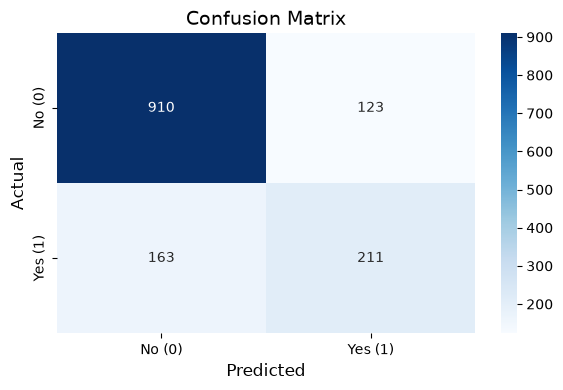

In [54]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No (0)', 'Yes (1)'],
    yticklabels=['No (0)', 'Yes (1)']
)

plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.title('Confusion Matrix', fontsize=14)
plt.tight_layout()
plt.show()

**Ответьте на вопросы:**
- Что показывает метрика `accuracy`? Почему в задачах с дисбалансом классов она может быть недостаточной?
- Что отображает `classification_report`? Какие метрики в нём наиболее важны для оценки качества бинарной классификации?
- Что показывает матрица ошибок (`confusion_matrix`)? Как с её помощью оценить, насколько хорошо модель различает классы?
- Какие значения отображаются в ячейках матрицы ошибок? Что означает каждый из четырёх квадрантов (TP, TN, FP, FN)?
- Как визуализация матрицы ошибок помогает лучше понять поведение модели?

##### **Ответы на вопросы:**

1. Accuracy — доля правильных предсказаний среди всех объектов. При дисбалансе классов высокая точность может достигаться преимущественно за счёт частого класса. В нашей выборке постоянное предсказание No дало бы около 73,4% точности, но не обнаружило бы ни одного случая оттока. У модели accuracy ≈ 79,7%, поэтому для оценки оттока нужны дополнительные метрики.
2. Отчёт показывает для каждого класса:
   - precision — долю верных предсказаний среди всех предсказаний этого класса;
   - recall — долю обнаруженных объектов среди всех реальных объектов класса;
   - f1-score — гармоническое среднее precision и recall;
   - support — количество объектов класса.
3. Матрица сопоставляет истинные классы с предсказанными и показывает количество правильных и ошибочных предсказаний каждого типа. Диагональные элементы соответствуют правильным ответам, остальные — ошибкам. Она позволяет отдельно оценить обнаружение оттока и распознавание оставшихся клиентов
4. Считая отток (Yes) положительным классом:
   - TP = 211 — клиент ушёл, модель предсказала уход.
   - TN = 910 — клиент остался, модель предсказала отсутствие оттока.
   - FP = 123 — клиент остался, но модель предсказала уход.
   - FN = 163 — клиент ушёл, но модель предсказала, что он останется.
5. Она позволяет быстро увидеть, какие ошибки преобладают и какой класс модель распознаёт хуже. В нашем случае модель пропускает 163 случая оттока из 374 — около 44%. Визуализация делает эту проблему заметной, хотя общая точность составляет почти 80%.

## **5. Подбор гиперпараметров для лучшей модели, ее обучение и оценка**

>Ознакомьтесь с теоретической информации прежде чем перейти к решению задачи:

**Подбор гиперпараметров с помощью `GridSearchCV`**

**Что такое `GridSearchCV`?**

`GridSearchCV` — это инструмент из библиотеки `scikit-learn`, который автоматически перебирает различные комбинации гиперпараметров модели, чтобы найти **наиболее эффективную** комбинацию.

**Зачем это нужно?**

Модель машинного обучения может давать разные результаты в зависимости от значений гиперпараметров (например, `C` - коэффициент регуляризации). Вручную перебирать все возможные комбинации бывает неудобно и долго. `GridSearchCV` делает это автоматизированно.

**Как это работает?**
- Вы задаёте **сетку параметров** — список возможных значений для каждого гиперпараметра.
- `GridSearchCV` обучает модель на каждой комбинации параметров, используя **кросс-валидацию** (например, 5-фолдную).
- В конце выбирается та комбинация, которая показала **лучший результат** (например, по метрике `f1`).

**Пример использования:**
```python
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Определяем сетку параметров
param_grid = [
    {'C': [0.1, 1, 10], 'penalty': ['l2']},
    {'C': [0.1, 1], 'penalty': ['l1'], 'solver': ['saga']}
]

# Создаём модель
model = LogisticRegression()

# Оборачиваем в GridSearchCV
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='f1')

# Обучаем
grid_search.fit(X_train, y_train)

# Получаем лучшую модель
best_model = grid_search.best_estimator_

**Баланс классов**

В задачах классификации часто встречается **дисбаланс классов** — один класс представлен значительно чаще другого (например, 90% "нет оттока", 10% "есть отток"). В таких случаях модель может "переобучаться" на более частом классе, игнорируя редкий.

`class_weight` — это параметр моделей классификации (например, `LogisticRegression`), который позволяет задать **веса для каждого класса**.

По умолчанию веса всех классов равны 1 (`class_weight=None`), что может привести к **переобучению** на более частом классе, если в данных есть **дисбаланс** (например, 90% "нет оттока", 10% "есть отток").

Параметр `class_weight='balanced'` автоматически **уравновешивает веса классов** во время обучения: чем реже класс встречается, тем больший вес он получает. Это помогает модели лучше "обращать внимание" на редкие классы и улучшает такие метрики, как `recall` и `f1`.


**Задание:**  
Для подбора гиперпараметров используйте объект класса `GridSearchCV` из `sklearn.model_selection`.
- Определите сетку параметров `param_grid`:
  - Для `penalty='l2'`: используйте `C = [0.01, 0.1, 1, 10, 100]`.
  - Для `penalty='l1'`: используйте `C = [0.01, 0.1, 1, 10]` и `solver='saga'`.
  - Установите `class_weight='balanced'` для обеих конфигураций.
- Создайте модель `LogisticRegression` с параметрами:
  - `max_iter=1000`, `random_state=42`.
- Создайте объект `GridSearchCV`, передав:
  - Модель, сетку параметров, количество фолдов (`cv=5`), метрику (`scoring='f1'`).
- Обучите `GridSearchCV` на обучающем множестве.
- Выведите лучшие параметры (`grid_search.best_params_`) и лучшую оценку F1 (`grid_search.best_score_`).

In [64]:
param_grid = [
    {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l2'],
        'class_weight': ['balanced'],
    },
    {
        'C': [0.01, 0.1, 1, 10],
        'penalty': ['l1'],
        'solver': ['saga'],
        'class_weight': ['balanced'],
    },
]

grid_model = LogisticRegression(max_iter=1000, random_state=42)
grid_search = GridSearchCV(
    grid_model,
    param_grid,
    cv=5,
    scoring='f1',
)
grid_search.fit(X_train_scaled, y_train)

print('Best parameters:', grid_search.best_params_)
print(f'Best CV F1: {grid_search.best_score_:.4f}')

/Users/generalsuslik/Documents/uni/bmstu_bac/sem_5/ml/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/generalsuslik/Documents/uni/bmstu_bac/sem_5/ml/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of

Best parameters: {'C': 1, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'saga'}
Best CV F1: 0.6331


/Users/generalsuslik/Documents/uni/bmstu_bac/sem_5/ml/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/generalsuslik/Documents/uni/bmstu_bac/sem_5/ml/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


**Задание:**
- Извлеките лучшую модель из `grid_search`, используя атрибут `best_estimator_`.
- Используя лучшую модель, сделайте предсказания на тестовых данных.
- Выведите метрики так же, как и в пункте 4:
  - Точность (Accuracy).
  - Отчет классификации.

In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)

print(f'Accuracy (best model): {accuracy_score(y_test, y_pred_best):.4f}')
print('Classification Report (best model):')
print(classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=['No', 'Yes'],
))

comparison = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision (Yes)': precision_score(y_test, predictions),
        'Recall (Yes)': recall_score(y_test, predictions),
        'F1 (Yes)': f1_score(y_test, predictions),
    }
    for name, predictions in [
        ('Baseline', y_pred),
        ('Best CV F1', y_pred_best),
    ]
]).set_index('Model')

display(comparison.round(4))

Accuracy (best model): 0.7249
Classification Report (best model):
              precision    recall  f1-score   support

          No       0.90      0.70      0.79      1033
         Yes       0.49      0.79      0.61       374

    accuracy                           0.72      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.72      0.74      1407



,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
Model,,,,
Baseline,0.7967,0.6317,0.5642,0.5960
Best CV F1,0.7249,0.4893,0.7941,0.6055


**Задание:**
- Аналогично постройте матрицу ошибок (`confusion_matrix`) для тестовых и предсказанных значений с лучшей моделью.
- Визуализируйте матрицу с помощью `sns.heatmap`:
  - Установите `annot=True`, чтобы отображать числа в ячейках.
  - Установите `fmt='d'`, чтобы отображать целые числа.

TN=723, FP=310, FN=77, TP=297


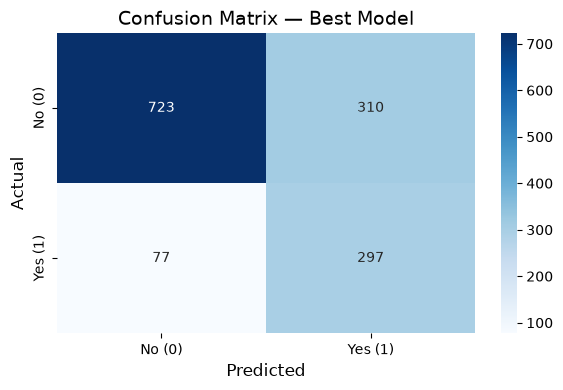

In [66]:
cm_best = confusion_matrix(y_test, y_pred_best, labels=[0, 1])
tn, fp, fn, tp = cm_best.ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_best,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No (0)', 'Yes (1)'],
    yticklabels=['No (0)', 'Yes (1)'],
)

plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.title('Confusion Matrix — Best Model', fontsize=14)
plt.tight_layout()
plt.show()

**Задание:**

- Извлеките коэффициенты обученной модели `best_model.coef_[0]`. Эти коэффициенты показывают влияние соответствующего признака на предсказание модели.
- Определите топ-10 признаков с наибольшей важностью (по **абсолютному значению** коэффициента). Это покажет, какие признаки сильнее всего влияют на решение модели.

In [67]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': best_model.coef_[0],
})
feature_importance['Importance'] = feature_importance['Coefficient'].abs()
feature_importance['Direction'] = np.select(
    [feature_importance['Coefficient'] > 0,
     feature_importance['Coefficient'] < 0],
    ['Increases churn odds', 'Decreases churn odds'],
    default='Zero coefficient',
)

top_features = feature_importance.sort_values(
    'Importance', ascending=False
).head(10)

display(top_features.reset_index(drop=True).round(4))

,Feature,Coefficient,Importance,Direction
0,tenure,-1.2439,1.2439,Decreases churn odds
1,TotalCharges,0.6002,0.6002,Increases churn odds
2,InternetService_Fiber optic,0.5081,0.5081,Increases churn odds
3,Contract_Month-to-month,0.3993,0.3993,Increases churn odds
4,MonthlyCharges,-0.3432,0.3432,Decreases churn odds
5,Contract_Two year,-0.2918,0.2918,Decreases churn odds
6,OnlineSecurity_No,0.1852,0.1852,Increases churn odds
7,StreamingTV_Yes,0.1660,0.1660,Increases churn odds
8,TechSupport_No,0.1632,0.1632,Increases churn odds
9,PaymentMethod_Electronic check,0.1613,0.1613,Increases churn odds


**Задание:**
- Постройте визуализацию важности признаков (для топ-10 по важности признаков) на основе абсолютных значений коэффициентов модели.
- Используйте столбчатую диаграмму (`sns.barplot`), где:
  - По оси X — абсолютные значения коэффициентов.
  - По оси Y — названия признаков.

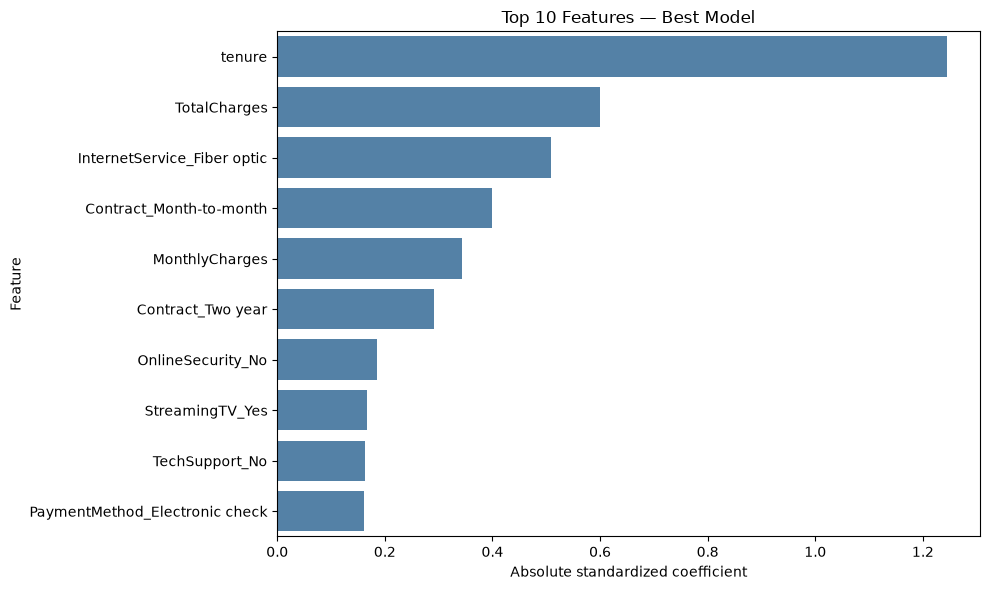

In [68]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature',
    order=top_features['Feature'].tolist(),
    color='steelblue',
)

plt.xlabel('Absolute standardized coefficient')
plt.ylabel('Feature')
plt.title('Top 10 Features — Best Model')
plt.tight_layout()
plt.show()

**Ответьте на вопросы:**
- Что такое `GridSearchCV` и зачем он используется? Как он помогает находить оптимальные гиперпараметры?
- В чём разница между `L1` и `L2` регуляризацией?
- Почему в `GridSearchCV` используется `scoring='f1'`?
- Что означает параметр `cv=5`?
- Как `class_weight='balanced'` влияет на обучение модели? Почему это важно при дисбалансе классов?
- Как интерпретировать коэффициенты логистической регрессии? Что означает положительный и отрицательный коэффициент?
- Почему для определения важности признаков используется **абсолютное значение** коэффициента, а не само значение?
- Какие признаки оказались наиболее значимыми?

##### **Ответы на вопросы:**

1. **Что такое GridSearchCV и зачем он используется?**
   GridSearchCV перебирает заданные комбинации гиперпараметров и оценивает каждую с помощью кросс-валидации. Выбирается комбинация с наибольшим средним значением выбранной метрики. По умолчанию лучшая модель затем заново обучается на всей переданной обучающей выборке. В этой работе проверены 9 комбинаций параметров, лучшие параметры: `C=1, class_weight='balanced', penalty='l1', solver='saga'`. Среднее F1 на кросс-валидации — 0.6331. Тестовая выборка при подборе параметров не используется.

2. **В чём разница между L1 и L2 регуляризацией?**
   L1 добавляет к функции потерь штраф за сумму абсолютных значений коэффициентов и может обнулять некоторые коэффициенты, выполняя отбор признаков. L2 штрафует сумму квадратов коэффициентов и уменьшает их величину, обычно не обнуляя их полностью. В LogisticRegression параметр C задаёт обратную силу регуляризации: чем меньше C, тем сильнее штраф.

3. **Почему используется scoring='f1'?**
   Классы несбалансированы, поэтому accuracy может быть высокой даже при плохом обнаружении оттока. F1 — гармоническое среднее precision и recall; при бинарной классификации с метками 0 и 1 scoring='f1' оценивает положительный класс Churn=1. Подбор ориентирован на сочетание точности предупреждений об оттоке и полноты обнаружения ушедших клиентов. Лучший результат на кросс-валидации не гарантирует наибольшую accuracy на тестовых данных.

4. **Что означает cv=5?**
   Обучающая выборка разделяется на пять частей. Для каждой комбинации параметров модель пять раз обучается на четырёх частях и проверяется на оставшейся; каждая часть используется для проверки один раз. Пять значений F1 усредняются. Для классификации GridSearchCV с целочисленным cv использует стратифицированное разбиение, сохраняющее примерно одинаковые доли классов. Отдельная тестовая выборка в этих пяти проверках не участвует.

5. **Как class_weight='balanced' влияет на обучение?**
   Веса классов задаются обратно пропорционально их частотам, поэтому ошибка на редком классе Yes получает больший вес. Это может повысить recall оттока, но одновременно увеличить число ложных предупреждений и снизить precision и accuracy. В нашем эксперименте recall класса Yes изменился с 0.56 до 0.79, precision — с 0.63 до 0.49, F1 — с 0.60 до 0.61. Улучшение F1 при балансировке не гарантируется для любого датасета.

6. **Как интерпретировать коэффициенты логистической регрессии?**
   Положительный коэффициент связан с увеличением шансов оттока, отрицательный — с уменьшением при фиксированных остальных признаках. Поскольку признаки стандартизованы, коэффициент показывает изменение логарифма шансов оттока при увеличении признака на одно стандартное отклонение. Это условная связь в обученной модели, а не доказательство причинного влияния. Среди полученных коэффициентов самый большой положительный у `TotalCharges` (0.6002), самый большой по модулю отрицательный — у `tenure` (-1.2439).

7. **Почему важность оценивается по абсолютному значению коэффициента?**
   Знак показывает направление связи, а модуль — её силу в модели. Большой отрицательный коэффициент может быть столь же значимым, как большой положительный. Поэтому топ-10 строится по модулю коэффициента, а исходный знак сохраняется в таблице для интерпретации. Сравнение проводится для стандартизованных признаков; при коррелирующих признаках коэффициенты могут перераспределяться между ними.

8. **Какие признаки оказались наиболее значимыми?**
   Топ-10 по убыванию абсолютных значений коэффициентов: `tenure`, `TotalCharges`, `InternetService_Fiber optic`, `Contract_Month-to-month`, `MonthlyCharges`, `Contract_Two year`, `OnlineSecurity_No`, `StreamingTV_Yes`, `TechSupport_No`, `PaymentMethod_Electronic check`. Их коэффициенты, абсолютные значения и направление связи приведены в таблице выше, а величины важности показаны на столбчатой диаграмме.

**Вывод по сравнению моделей.** Точность базовой модели — 0.7967, выбранной по CV F1 — 0.7249. F1 для оттока изменился с 0.5960 до 0.6055. Матрица ошибок выбранной модели: TN=723, FP=310, FN=77, TP=297. Модель обнаруживает больше случаев оттока, но выдаёт больше ложных предупреждений. Выбор модели зависит от стоимости пропущенного оттока и ошибочного предупреждения.